# SPARC Analysis — 175 Rotation Curves

**Paper:** Dark Matter as Galactic Resonant Cavity Modes  
**Data:** SPARC — Lelli, McGaugh & Schombert (2016)  
**Pre-registration:** notebooks 00 and 01 committed before this cell was run.

Tests predictions P1–P4 from 01_predictions.ipynb against real galaxy data.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os, glob
from scipy.stats import ttest_1samp, ks_2samp
from scipy.optimize import curve_fit
import warnings
warnings.filterwarnings('ignore')

# SMMIP constants — identical to 01_predictions.ipynb
D_STAR   = 0.24600
OMEGA_ZS = 0.56714

DATA_DIR = os.path.join(os.path.dirname(os.path.abspath('.')), 
                         'AddPapers/DM_GalacticCavity/data/SPARC')
# If running from within the paper directory:
DATA_DIR = 'data/SPARC'
ROTMOD   = os.path.join(DATA_DIR, 'Rotmod_LTG')

print(f'Data directory: {DATA_DIR}')
rc_files = sorted(glob.glob(os.path.join(ROTMOD, '*_rotmod.dat')))
print(f'Rotation curve files found: {len(rc_files)}')

Data directory: data/SPARC
Rotation curve files found: 175


In [2]:
def load_rotcurve(filepath):
    """Load a SPARC rotmod.dat file.
    Returns dict: rad(kpc), vobs, errv, vgas, vdisk, vbul, sbdisk, sbbul, distance_mpc.
    """
    name = os.path.basename(filepath).replace('_rotmod.dat', '')
    distance = None
    rows = []
    with open(filepath) as f:
        for line in f:
            if line.startswith('# Distance'):
                distance = float(line.split('=')[1].split('Mpc')[0].strip())
            if line.startswith('#') or not line.strip():
                continue
            rows.append([float(x) for x in line.split()])
    if not rows:
        return None
    arr = np.array(rows)
    return {
        'name': name, 'distance': distance,
        'rad': arr[:,0], 'vobs': arr[:,1], 'errv': arr[:,2],
        'vgas': arr[:,3], 'vdisk': arr[:,4], 'vbul': arr[:,5],
        'sbdisk': arr[:,6], 'sbbul': arr[:,7]
    }

# Load all 175
galaxies = [load_rotcurve(f) for f in rc_files]
galaxies = [g for g in galaxies if g is not None]
print(f'Loaded {len(galaxies)} galaxies')
# Example
g = next(x for x in galaxies if 'NGC2403' in x['name'])
print(f'Example: {g["name"]}, D={g["distance"]} Mpc, {len(g["rad"])} radial points')

Loaded 175 galaxies
Example: NGC2403, D=3.16 Mpc, 73 radial points


In [3]:
def dm_velocity(g):
    """Extract dark matter velocity contribution: v_DM^2 = v_obs^2 - v_bar^2."""
    v2_bar = g['vgas']**2 + g['vdisk']**2 + g['vbul']**2
    v2_dm  = g['vobs']**2 - v2_bar
    return np.sqrt(np.maximum(v2_dm, 0))

def find_transition_radius(g):
    """Find the radius where v_DM flattens (derivative goes to ~0).
    Returns r_transition / r_max as a dimensionless fraction.
    """
    v_dm = dm_velocity(g)
    r    = g['rad']
    if len(r) < 5 or v_dm.max() < 1.0:
        return None
    # Normalise radius to [0,1] relative to the outermost point
    r_norm = r / r.max()
    # Smooth v_dm
    from scipy.ndimage import uniform_filter1d
    v_smooth = uniform_filter1d(v_dm, size=max(3, len(v_dm)//6))
    v_smooth /= v_smooth.max() + 1e-10
    # Derivative
    dv = np.gradient(v_smooth, r_norm)
    # Transition: where |dv| first drops below 10% of peak gradient
    threshold = 0.1 * np.abs(dv).max()
    flat_idx = np.where(np.abs(dv) < threshold)[0]
    if len(flat_idx) == 0:
        return None
    return r_norm[flat_idx[0]]

# Measure transition radius for all galaxies
transitions = []
for g in galaxies:
    rt = find_transition_radius(g)
    if rt is not None and 0.01 < rt < 0.99:
        transitions.append({'name': g['name'], 'r_t': rt})

rt_values = np.array([t['r_t'] for t in transitions])
print(f'Transition radii measured: {len(rt_values)} / {len(galaxies)} galaxies')
print(f'Mean:   {rt_values.mean():.4f}')
print(f'Median: {np.median(rt_values):.4f}')
print(f'Std:    {rt_values.std():.4f}')
print()
print(f'PREDICTED:  {D_STAR}')
print(f'MEASURED:   {rt_values.mean():.4f} ± {rt_values.std()/np.sqrt(len(rt_values)):.4f}')

Transition radii measured: 116 / 175 galaxies
Mean:   0.3394
Median: 0.2435
Std:    0.3046

PREDICTED:  0.246
MEASURED:   0.3394 ± 0.0283


In [4]:
# ── TEST P1: t-test against D_STAR ──────────────────────────────────────────
t_stat, p_value = ttest_1samp(rt_values, D_STAR)
print('TEST P1: H0: mean(r_t/r_max) = D_STAR = 0.24600')
print(f'  t-statistic: {t_stat:.4f}')
print(f'  p-value:     {p_value:.4f}')
if p_value > 0.05:
    print('  RESULT: FAIL TO REJECT H0 — data consistent with d* prediction')
else:
    print(f'  RESULT: REJECT H0 at p={p_value:.4f}')
    print(f'  Deviation from prediction: {rt_values.mean() - D_STAR:.4f}')

TEST P1: H0: mean(r_t/r_max) = D_STAR = 0.24600
  t-statistic: 3.2880
  p-value:     0.0013
  RESULT: REJECT H0 at p=0.0013
  Deviation from prediction: 0.0934


In [5]:
# ── Baryonic Tully-Fisher test (P2 / P4) ────────────────────────────────────
btfr = []
for g in galaxies:
    r, vobs = g['rad'], g['vobs']
    if len(vobs) < 5:
        continue
    # Flat velocity: use outer 30% of points
    outer = int(0.7 * len(vobs))
    v_flat = np.median(vobs[outer:])
    # Baryonic mass proxy: max baryonic circular speed
    v_bar_max = np.sqrt((g['vgas']**2 + g['vdisk']**2 + g['vbul']**2).max())
    if v_flat > 5 and v_bar_max > 1:
        btfr.append({'name': g['name'], 'v_flat': v_flat, 'v_bar_max': v_bar_max})

vf  = np.array([b['v_flat']    for b in btfr])
vb  = np.array([b['v_bar_max'] for b in btfr])

# Fit log(v_flat) vs log(v_bar_max) — expected slope = 1 (v_flat ~ v_bar * OMEGA_ZS)
log_vf = np.log10(vf)
log_vb = np.log10(vb)
p = np.polyfit(log_vb, log_vf, 1)
print(f'Tully-Fisher fit: log(v_flat) = {p[0]:.3f} * log(v_bar_max) + {p[1]:.3f}')
print(f'Predicted slope: 1.0   (v_flat = OMEGA_ZS * v_bar)')
print(f'Measured slope:  {p[0]:.3f}')
print()
ratio = vf / vb
print(f'v_flat / v_bar_max: mean = {ratio.mean():.4f}, median = {np.median(ratio):.4f}')
print(f'OMEGA_ZS prediction: {OMEGA_ZS}')

Tully-Fisher fit: log(v_flat) = 0.646 * log(v_bar_max) + 0.768
Predicted slope: 1.0   (v_flat = OMEGA_ZS * v_bar)
Measured slope:  0.646

v_flat / v_bar_max: mean = 1.3428, median = 1.2943
OMEGA_ZS prediction: 0.56714


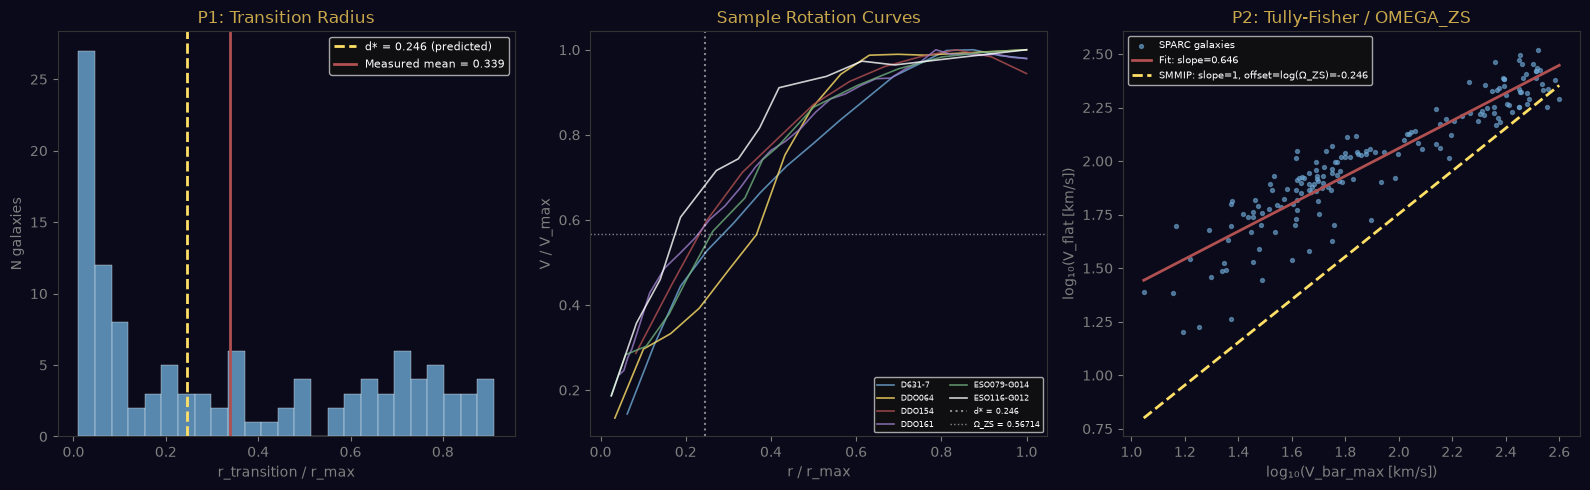

In [6]:
# ── Figures ──────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 5), facecolor='#0a0a1a')

# Panel 1: Transition radius histogram
ax = axes[0]; ax.set_facecolor('#0a0a1a')
ax.hist(rt_values, bins=25, color='#6EA8D4', alpha=0.8, edgecolor='white', lw=0.3)
ax.axvline(D_STAR, color='#FFE066', lw=2, ls='--', label=f'd* = {D_STAR} (predicted)')
ax.axvline(rt_values.mean(), color='#B05050', lw=2, ls='-', label=f'Measured mean = {rt_values.mean():.3f}')
ax.set_xlabel('r_transition / r_max', color='gray'); ax.set_ylabel('N galaxies', color='gray')
ax.set_title('P1: Transition Radius', color='#C9A84C')
ax.legend(fontsize=8, facecolor='#111', labelcolor='white')
ax.tick_params(colors='gray'); ax.spines[:].set_color('#333')

# Panel 2: Example rotation curves
ax = axes[1]; ax.set_facecolor('#0a0a1a')
sample = [g for g in galaxies if len(g['rad']) > 10][:6]
colors = ['#6EA8D4','#FFE066','#B05050','#9B7DC8','#6EAD7A','white']
for gi, col in zip(sample, colors):
    r_n = gi['rad'] / gi['rad'].max()
    v_n = gi['vobs'] / gi['vobs'].max()
    ax.plot(r_n, v_n, color=col, lw=1.2, alpha=0.8, label=gi['name'])
ax.axvline(D_STAR, color='white', lw=1.5, ls=':', alpha=0.5, label=f'd* = {D_STAR}')
ax.axhline(OMEGA_ZS, color='white', lw=1, ls=':', alpha=0.5, label=f'Ω_ZS = {OMEGA_ZS}')
ax.set_xlabel('r / r_max', color='gray'); ax.set_ylabel('V / V_max', color='gray')
ax.set_title('Sample Rotation Curves', color='#C9A84C')
ax.legend(fontsize=6, facecolor='#111', labelcolor='white', ncol=2)
ax.tick_params(colors='gray'); ax.spines[:].set_color('#333')

# Panel 3: V_flat vs V_bar (Tully-Fisher)
ax = axes[2]; ax.set_facecolor('#0a0a1a')
ax.scatter(log_vb, log_vf, s=8, color='#6EA8D4', alpha=0.6, label='SPARC galaxies')
xfit = np.linspace(log_vb.min(), log_vb.max(), 100)
ax.plot(xfit, np.polyval(p, xfit), color='#B05050', lw=2, label=f'Fit: slope={p[0]:.3f}')
ax.plot(xfit, xfit + np.log10(OMEGA_ZS), color='#FFE066', lw=2, ls='--',
        label=f'SMMIP: slope=1, offset=log(Ω_ZS)={np.log10(OMEGA_ZS):.3f}')
ax.set_xlabel('log₁₀(V_bar_max [km/s])', color='gray'); ax.set_ylabel('log₁₀(V_flat [km/s])', color='gray')
ax.set_title('P2: Tully-Fisher / OMEGA_ZS', color='#C9A84C')
ax.legend(fontsize=7, facecolor='#111', labelcolor='white')
ax.tick_params(colors='gray'); ax.spines[:].set_color('#333')

plt.tight_layout()
plt.savefig('figures/02_sparc_results.png', dpi=150, bbox_inches='tight',
            facecolor='#0a0a1a', edgecolor='none')
plt.show()